# Graph — GCN (Graph Convolutional Network) dengan torch biasa
**Kapan dipakai:** klasifikasi simpul saat label **sedikit** (misal 20 per kelas) tapi koneksi
antar simpul ada. Tanpa paket torch_geometric.

**Idenya:** tiap simpul merata-rata feature tetangganya. 2 lapis = informasi dari tetangga
sampai 2 langkah. Rumus satu lapis: H' = relu(Â · H · W), dengan Â = D^-1/2 (A + I) D^-1/2
(A = matriks sisi, I = sisi ke diri sendiri, D = derajat).

**Langkah:**
1. Bangun matriks graf Â.
2. Latih GCN 2 lapis; loss hanya dari simpul berlabel; simpan bobot dengan validasi terbaik.
3. Evaluasi di simpul uji, simpan prediksi. Pembanding: MLP tanpa graf (Â = identitas).

**Data demo:** Cora (2.708 makalah, 7 topik, feature kata `w0..w1432`, sisi = sitasi).

In [1]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, classification_report, f1_score
from torch import nn

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/graph/cora"   # GANTI saat lomba
NODES_CSV = f"{DATA_FOLDER}/nodes.csv"
EDGES_CSV = f"{DATA_FOLDER}/edges.csv"

NODE_ID_COL = "id"
SOURCE_COL = "source"
TARGET_COL = "target"
LABEL_COL = "label"
TRAIN_PER_CLASS = 20    # label yang diketahui per kelas (sisanya dianggap tanpa label)
N_VAL = 500             # simpul validasi untuk memilih epoch terbaik
HIDDEN = 16
DROPOUT = 0.5
EPOCHS = 200
SEED = 42

## Baca data

In [3]:
nodes = pd.read_csv(NODES_CSV)
edges = pd.read_csv(EDGES_CSV)
print(nodes.shape, edges.shape)
print(nodes[LABEL_COL].value_counts())

(2708, 1435) (5429, 2)
label
Neural_Networks           818
Probabilistic_Methods     426
Genetic_Algorithms        418
Theory                    351
Case_Based                298
Reinforcement_Learning    217
Rule_Learning             180
Name: count, dtype: int64


## Langkah 1 — matriks graf Â
`adjacency[i, k] = 1` bila simpul baris i dan k tersambung. Diagonal diisi 1 (sisi ke diri
sendiri) supaya feature simpul itu sendiri ikut dirata-rata.

In [4]:
n_nodes = len(nodes)
row_of = {}                          # id simpul -> nomor baris
for row, node in enumerate(nodes[NODE_ID_COL]):
    row_of[node] = row
adjacency = np.zeros((n_nodes, n_nodes), dtype=np.float32)
for source, target in zip(edges[SOURCE_COL], edges[TARGET_COL]):
    adjacency[row_of[source], row_of[target]] = 1
    adjacency[row_of[target], row_of[source]] = 1     # graf tak berarah
np.fill_diagonal(adjacency, 1)

degree = adjacency.sum(axis=1)
scale = np.diag(1 / np.sqrt(degree))               # D^-1/2
A_norm = torch.tensor(scale @ adjacency @ scale)   # Â gaya GCN
A_mean = torch.tensor(np.diag(1 / degree) @ adjacency)   # rata-rata tetangga biasa
identity = torch.eye(n_nodes)                      # tanpa graf = MLP biasa
print("derajat rata-rata:", round(degree.mean() - 1, 2))

derajat rata-rata: 3.9


## Feature, label, dan split (20 label per kelas, 500 validasi, sisanya uji)
Feature kata dinormalkan per baris (jumlah per simpul = 1).

In [5]:
features = nodes.drop(columns=[NODE_ID_COL, LABEL_COL]).to_numpy(dtype=np.float32)
row_sums = features.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
X = torch.tensor(features / row_sums)
codes, class_names = pd.factorize(nodes[LABEL_COL])   # label teks -> nomor kelas
y = torch.tensor(codes)

train_nodes = nodes.groupby(LABEL_COL).sample(TRAIN_PER_CLASS, random_state=SEED)
train_rows = train_nodes.index.to_numpy()
other_rows = np.setdiff1d(np.arange(n_nodes), train_rows)
rng = np.random.default_rng(SEED)
other_rows = rng.permutation(other_rows)
val_rows = other_rows[:N_VAL]
test_rows = other_rows[N_VAL:]
print("train:", len(train_rows), "| validasi:", len(val_rows), "| uji:", len(test_rows))

train: 140 | validasi: 500 | uji: 2068


## Langkah 2a — model
Pilih SATU matriks graf: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [6]:
torch.manual_seed(SEED)
layer1 = nn.Linear(X.shape[1], HIDDEN)
layer2 = nn.Linear(HIDDEN, len(class_names))
dropout = nn.Dropout(DROPOUT)
all_layers = nn.ModuleList([layer1, layer2, dropout])   # .train()/.eval() ikut ke dropout
graph_matrix = A_norm               # GCN
# graph_matrix = A_mean             # rata-rata tetangga biasa (gaya GraphSAGE-mean)
# graph_matrix = identity           # MLP tanpa graf (pembanding)


def forward(inputs):
    hidden = layer1(dropout(inputs))
    hidden = torch.relu(graph_matrix @ hidden)    # campur dengan tetangga
    output = layer2(dropout(hidden))
    return graph_matrix @ output                  # campur sekali lagi


# coba: keluar satu baris skor per simpul, satu kolom per kelas
print(forward(X).shape)

torch.Size([2708, 7])


## Langkah 2b — latih
Loss hanya dari simpul berlabel. Tiap epoch dicek akurasi validasi; bobot terbaik disimpan.

akurasi validasi terbaik: 0.828


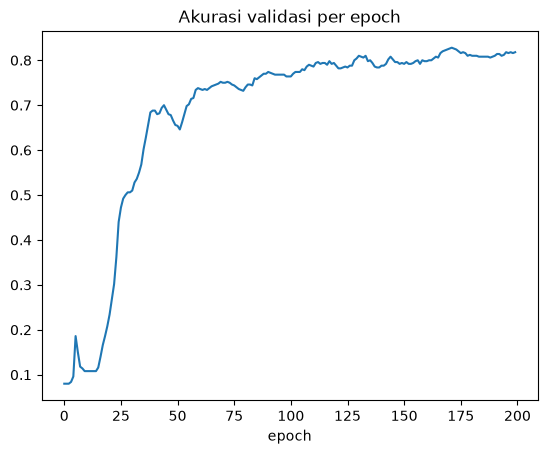

In [7]:
optimizer = torch.optim.Adam(all_layers.parameters(), lr=0.01, weight_decay=5e-4)
best_accuracy = 0
history = []
for epoch in range(EPOCHS):
    all_layers.train()
    optimizer.zero_grad()
    scores = forward(X)
    loss = nn.functional.cross_entropy(scores[train_rows], y[train_rows])
    loss.backward()
    optimizer.step()

    all_layers.eval()
    with torch.no_grad():
        scores = forward(X)
    val_pred = scores[val_rows].argmax(dim=1)
    val_accuracy = accuracy_score(y[val_rows], val_pred)
    history.append(val_accuracy)
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_weights = copy.deepcopy(all_layers.state_dict())

all_layers.load_state_dict(best_weights)
print("akurasi validasi terbaik:", round(best_accuracy, 4))
plt.plot(history)
plt.title("Akurasi validasi per epoch")
plt.xlabel("epoch")
plt.show()

## Evaluasi di simpul uji

In [8]:
all_layers.eval()
with torch.no_grad():
    scores = forward(X)
predicted_codes = scores.argmax(dim=1)
predicted_codes = predicted_codes.numpy()
y_test = class_names[codes[test_rows]]               # nomor kelas -> nama kelas
pred_test = class_names[predicted_codes[test_rows]]
print("Akurasi uji:", round(accuracy_score(y_test, pred_test), 4))
print("F1 macro uji:", round(f1_score(y_test, pred_test, average="macro"), 4))
print(classification_report(y_test, pred_test))

Akurasi uji: 0.8071


F1 macro uji: 0.7988
                        precision    recall  f1-score   support

            Case_Based       0.82      0.77      0.79       224
    Genetic_Algorithms       0.95      0.92      0.93       328
       Neural_Networks       0.90      0.74      0.81       644
 Probabilistic_Methods       0.81      0.82      0.81       334
Reinforcement_Learning       0.71      0.89      0.79       158
         Rule_Learning       0.74      0.76      0.75       120
                Theory       0.61      0.82      0.70       260

              accuracy                           0.81      2068
             macro avg       0.79      0.82      0.80      2068
          weighted avg       0.82      0.81      0.81      2068



## Langkah 3 — simpan prediksi simpul uji

In [9]:
submission = pd.DataFrame()
submission["id"] = nodes[NODE_ID_COL][test_rows]
submission["label"] = pred_test
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
2455,2455,Theory
1773,1773,Neural_Networks
1613,1613,Probabilistic_Methods
1782,1782,Reinforcement_Learning
462,462,Neural_Networks
